# Titanic Survival Analysis

## Project Objective
The objective of this project is to analyze the Titanic passenger dataset and identify factors associated with passenger survival.

## Tools and Libraries
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Titanic-Dataset.csv")

display(df.head())

print("Dataset shape:", df.shape)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Dataset shape: (891, 12)


In [24]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nSummary statistics:")
display(df.describe())

Dataset shape: (891, 12)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Summary statistics:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [25]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values)

missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nPercentage of missing values:")
display(missing_percentage.round(2))

Missing values in each column:


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


Percentage of missing values:


PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.87
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
Cabin          77.10
Embarked        0.22
dtype: float64

In [26]:
df_clean = df.copy()

df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())

df_clean["Embarked"] = df_clean["Embarked"].fillna(
    df_clean["Embarked"].mode()[0]
)

df_clean = df_clean.drop(columns=["Cabin"])

print("Missing values after cleaning:")
display(df_clean.isnull().sum())

print("\nCleaned dataset shape:", df_clean.shape)

Missing values after cleaning:


PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


Cleaned dataset shape: (891, 11)


In [27]:
survival_counts = df_clean["Survived"].value_counts().sort_index()

print("Survival counts:")
print("Did not survive (0):", survival_counts.get(0, 0))
print("Survived (1):", survival_counts.get(1, 0))

survival_percentage = df_clean["Survived"].value_counts(normalize=True) * 100

print("\nSurvival percentages:")
print("Did not survive:", round(survival_percentage.get(0, 0), 2), "%")
print("Survived:", round(survival_percentage.get(1, 0), 2), "%")

Survival counts:
Did not survive (0): 549
Survived (1): 342

Survival percentages:
Did not survive: 61.62 %
Survived: 38.38 %


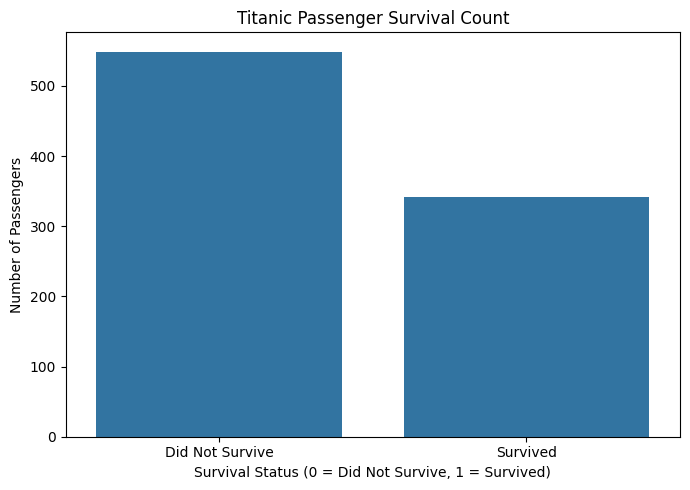

In [28]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="Survived")

plt.title("Titanic Passenger Survival Count")
plt.xlabel("Survival Status (0 = Did Not Survive, 1 = Survived)")
plt.ylabel("Number of Passengers")
plt.xticks([0, 1], ["Did Not Survive", "Survived"])

plt.tight_layout()
plt.savefig("survival_count.png", dpi=300, bbox_inches="tight")
plt.show()

Survival rate by sex:


Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

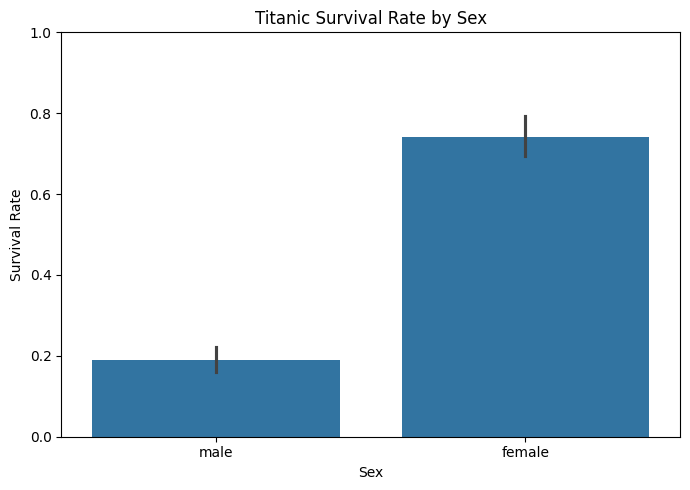

In [29]:
survival_by_sex = df_clean.groupby("Sex")["Survived"].mean() * 100

print("Survival rate by sex:")
display(survival_by_sex.round(2))

plt.figure(figsize=(7, 5))

sns.barplot(data=df_clean, x="Sex", y="Survived")

plt.title("Titanic Survival Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig("survival_by_sex.png", dpi=300, bbox_inches="tight")
plt.show()

Survival rate by passenger class:


Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64

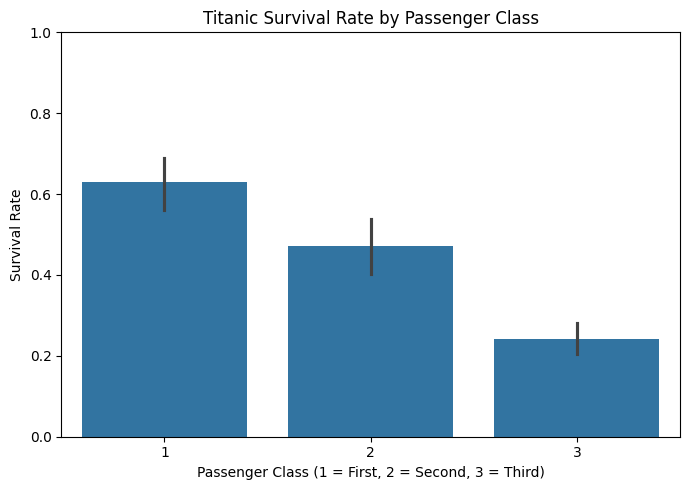

In [30]:
survival_by_class = df_clean.groupby("Pclass")["Survived"].mean() * 100

print("Survival rate by passenger class:")
display(survival_by_class.round(2))

plt.figure(figsize=(7, 5))

sns.barplot(data=df_clean, x="Pclass", y="Survived")

plt.title("Titanic Survival Rate by Passenger Class")
plt.xlabel("Passenger Class (1 = First, 2 = Second, 3 = Third)")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig("survival_by_class.png", dpi=300, bbox_inches="tight")
plt.show()

Passenger age statistics:


count    891.00
mean      29.36
std       13.02
min        0.42
25%       22.00
50%       28.00
75%       35.00
max       80.00
Name: Age, dtype: float64

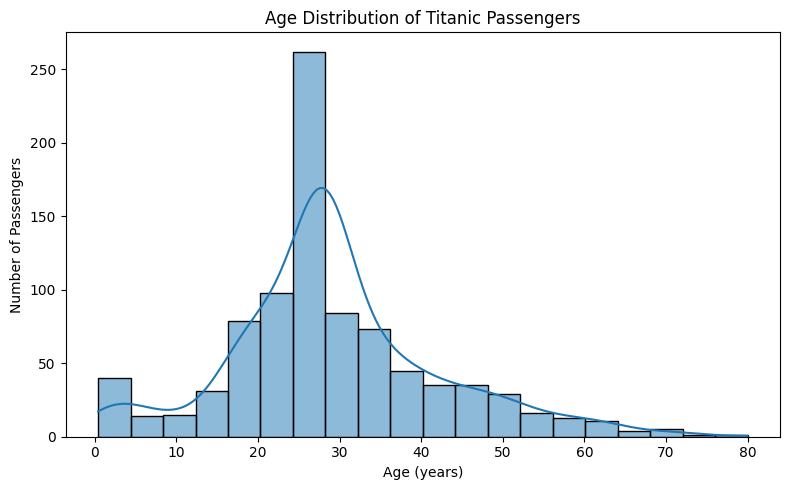

In [31]:
print("Passenger age statistics:")
display(df_clean["Age"].describe().round(2))

plt.figure(figsize=(8, 5))

sns.histplot(data=df_clean, x="Age", bins=20, kde=True)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age (years)")
plt.ylabel("Number of Passengers")

plt.tight_layout()
plt.savefig("age_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

Survival rate by age group (%):


AgeGroup
Child          57.97
Teenager       42.86
Young Adult    35.33
Adult          40.00
Senior         22.73
Name: Survived, dtype: float64

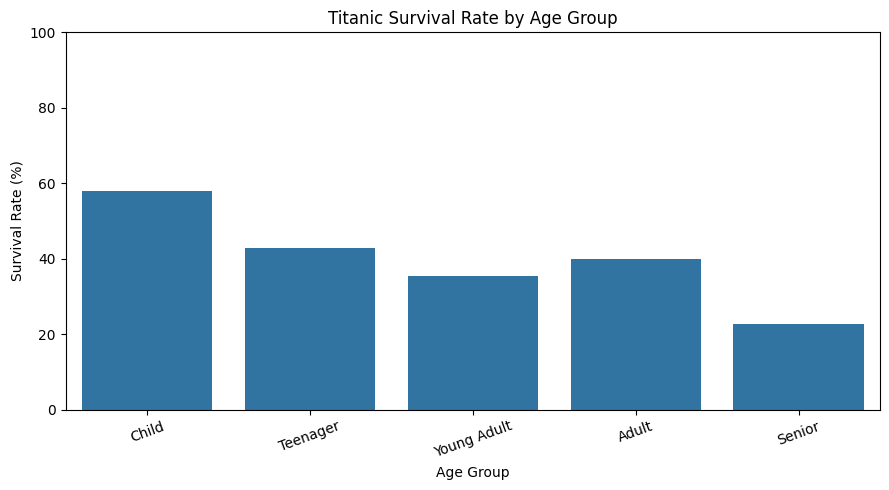

In [32]:
df_clean["AgeGroup"] = pd.cut(
    df_clean["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"],
    include_lowest=True
)

survival_by_age = df_clean.groupby(
    "AgeGroup", observed=False
)["Survived"].mean() * 100

print("Survival rate by age group (%):")
display(survival_by_age.round(2))

plt.figure(figsize=(9, 5))

sns.barplot(x=survival_by_age.index, y=survival_by_age.values)

plt.title("Titanic Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=20)
plt.ylim(0, 100)

plt.tight_layout()
plt.savefig("survival_by_age_group.png", dpi=300, bbox_inches="tight")
plt.show()

In [33]:
# Overall survival statistics
total_passengers = len(df_clean)
survivors = int(df_clean["Survived"].sum())
non_survivors = total_passengers - survivors

print("KEY FINDINGS")
print("-" * 35)
print("Total passengers:", total_passengers)
print("Survivors:", survivors)
print("Did not survive:", non_survivors)
print("Overall survival rate:", round(df_clean["Survived"].mean() * 100, 2), "%")

print("\nSurvival rate by sex (%):")
display((df_clean.groupby("Sex")["Survived"].mean() * 100).round(2))

print("\nSurvival rate by passenger class (%):")
display((df_clean.groupby("Pclass")["Survived"].mean() * 100).round(2))

print("\nSurvival rate by age group (%):")
display((df_clean.groupby("AgeGroup", observed=False)["Survived"].mean() * 100).round(2))

KEY FINDINGS
-----------------------------------
Total passengers: 891
Survivors: 342
Did not survive: 549
Overall survival rate: 38.38 %

Survival rate by sex (%):


Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


Survival rate by passenger class (%):


Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


Survival rate by age group (%):


AgeGroup
Child          57.97
Teenager       42.86
Young Adult    35.33
Adult          40.00
Senior         22.73
Name: Survived, dtype: float64

## Conclusion

This project uses Python to analyze the Titanic passenger dataset. The analysis examines overall survival, differences by sex and passenger class, and survival patterns across age groups.

The results help identify which passenger characteristics were associated with survival in this dataset.

## Key Findings

- A total of 891 passengers were included in the analysis.
- 342 passengers survived, while 549 did not survive.
- The overall survival rate was 38.38%.
- Female passengers had a survival rate of 74.20%, compared with 18.89% for male passengers.
- First-class passengers had the highest survival rate (62.96%), followed by second-class passengers (47.28%) and third-class passengers (24.24%).
- Children had the highest survival rate among the analyzed age groups (57.97%), while seniors had the lowest (22.73%).

## Limitations

- Some passenger ages were missing and were filled using the median age.
- The Cabin column was removed because it contained many missing values.
- The analysis identifies patterns and associations; it does not prove causation.
- Missing-value handling and the selected age-group boundaries may affect the results.